## Explore Temperature sensitivity to LE and LAI
Differentiating between water-limited and energy-limited ecosystems

In [1]:
import os
import glob
import netCDF4 as nc

import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import cm
import cartopy as cart
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point
import seaborn as sns

import numpy as np
import xarray as xr
import cftime
import pandas as pd

# Regridding
# import xesmf as xe

from lumip_utils import regime_limit


In [2]:
# NOTE (revision): data_path/out_path for "locale_mc" fixed from the stale
# .../Desktop/afforestation_LUMIP/... in the original to .../Documents/afforestation_LUMIP/...
# -- that's where the data actually lives; the original path would have failed on the
# very first data-loading cell below.
work = "locale_mc" # or "levante"

if work == "levante":
    data_path = "/home/m/m301093/data/clean/"
    out_path = "/home/m/m301093/results_biophys/"
if work == "locale_wnd":
    data_path = "G:/My Drive/MPIM/data/"
    out_path = "G:/My Drive/MPIM/Figures/"
if work == "locale_mc":
    data_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/data/"
    out_path = "/Users/matteomastropierro/Documents/afforestation_LUMIP/Submission/Figures/"

## Functions

In [3]:
def xr_fix_time(xr_in, date_start, date_end):
    
    if xr_in['time'].dt.calendar == 'noleap' or xr_in['time'].dt.calendar == '360_day':
        xr_in = xr_in.convert_calendar(calendar = 'gregorian', align_on = 'date')
        
    else: None
    
    time = pd.date_range(start=date_start, end=date_end, freq='M').to_numpy(dtype='datetime64[ns]')
    xr_out = xr_in.assign_coords(time = time)
    
    return xr_out

In [4]:
def xr_clean(xr_in, dims):
    data = xr_in.copy()
    for i,d in enumerate(dims):
        if d in data.coords and d in data.dims:
            data = data.drop(d)
            data = data.isel({d : 0})
        if d in data.coords:
            data = data.drop(d)
        if d in data.dims and d not in data.coords:
            data = data.isel({d : 0})
        if data.attrs == {}:
            None
        else:
            if d in data.data_vars:
                data = data.drop_vars(d)
    xr_out = data
    return xr_out

In [5]:
def lon180(ds):
    ds.coords['lon'] = (ds.coords['lon'] + 180) % 360 - 180
    ds = ds.sortby(ds.lon)
    return ds

In [6]:
def xr_multimodel_sign(xr_in, models):
    # Computes the Multimodel MEAN and STD
    # xr_in: list of xarray models
    mm = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override")
    
    std = xr.concat(xr_in, dim = "esm", coords = "minimal", compat = "override").std(dim = "esm")
    
    # Multimodel agreement in the sign of the sensitivity
    sign = xr.where(mm > 0, 1, -1)
    agreement = (np.abs(sign.sum(dim = "esm")/len(models)))
    
    mean = mm.mean(dim = "esm")
    return (mean, std, agreement)

In [7]:
def cell_weight(ds):
    R = 6.371e6
    dϕ = np.deg2rad(ds.lat[1] - ds.lat[0])
    dλ = np.deg2rad(ds.lon[1] - ds.lon[0])
    dlat = R * dϕ * xr.ones_like(ds.lon)
    dlon = R * dλ * np.cos(np.deg2rad(ds.lat))
    cell_area = dlon * dlat
    return(cell_area)

In [8]:
def detrend_dim(da, dim, degree):
    # detrend along a single dimension
    p = da.polyfit(dim=dim, deg=degree)
    fit = xr.polyval(da[dim], p.polyfit_coefficients)
    da_det = (da - fit)
    return da_det

In [9]:
#### --------- Mann-Whitney Test --------- ####
from scipy.stats import mannwhitneyu

# Test applied on a grid-cell basis. For every gid-cell, the statistical difference between two time series is computed.
# 1st time series: Nino years' (DS_models_hist_nino)
# 2nd time series: Reference climatology (DS_models_hist_clim or DS_models_hist_clim_neutral)  

## -- Function for grid-cell operations -- ##
def multi_apply_along_axis(func1d, axis, arrs, *args, **kwargs):
    """
    Given a function `func1d(A, B, C, ..., *args, **kwargs)`  that acts on 
    multiple one dimensional arrays, apply that function to the N-dimensional
    arrays listed by `arrs` along axis `axis`
    
    If `arrs` are one dimensional this is equivalent to::
    
        func1d(*arrs, *args, **kwargs)
    
    If there is only one array in `arrs` this is equivalent to::
    
        numpy.apply_along_axis(func1d, axis, arrs[0], *args, **kwargs)
        
    All arrays in `arrs` must have compatible dimensions to be able to run
    `numpy.concatenate(arrs, axis)`
    
    Arguments:
        func1d:   Function that operates on `len(arrs)` 1 dimensional arrays,
                  with signature `f(*arrs, *args, **kwargs)`
        axis:     Axis of all `arrs` to apply the function along
        arrs:     Iterable of numpy arrays
        *args:    Passed to func1d after array arguments
        **kwargs: Passed to func1d as keyword arguments
    """
    # Concatenate the input arrays along the calculation axis to make one big
    # array that can be passed in to `apply_along_axis`
    carrs = np.concatenate(arrs, axis)
    
    # We'll need to split the concatenated arrays up before we apply `func1d`,
    # here's the offsets to split them back into the originals
    offsets=[]
    start=0
    for i in range(len(arrs)-1):
        start += arrs[i].shape[axis]
        offsets.append(start)
            
    # The helper closure splits up the concatenated array back into the components of `arrs`
    # and then runs `func1d` on them
    def helperfunc(a, *args, **kwargs):
        arrs = np.split(a, offsets)
        return func1d(*[*arrs, *args], **kwargs)
    
    # Run `apply_along_axis` along the concatenated array
    return np.apply_along_axis(helperfunc, axis, carrs, *args, **kwargs)


def xr_multipletest(p, alpha=0.05, method='fdr_bh', **multipletests_kwargs):
    """Apply statsmodels.stats.multitest.multipletests for multi-dimensional xr.objects."""
    from statsmodels.stats.multitest import multipletests
    # stack all to 1d array
    p_stacked = p.stack(s=p.dims)
    # mask only where not nan: https://github.com/statsmodels/statsmodels/issues/2899
    mask = np.isfinite(p_stacked)
    pvals_corrected = np.full(p_stacked.shape, np.nan)
    reject = np.full(p_stacked.shape, np.nan)
    # apply test where mask
    reject[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[0]
    pvals_corrected[mask] = multipletests(
        p_stacked[mask], alpha=alpha, method=method, **multipletests_kwargs)[1]

    def unstack(reject, p_stacked):
        """Exchange values from p_stacked with reject (1d array) and unstack."""
        xreject = p_stacked.copy()
        xreject.values = reject
        xreject = xreject.unstack()
        return xreject

    reject = unstack(reject, p_stacked)
    pvals_corrected = unstack(pvals_corrected, p_stacked)
    return reject, pvals_corrected


In [10]:
def lag_linregress_3D(x, y, lagx=0, lagy=0):
    """
    Input: Two xr.Datarrays of any dimensions with the first dim being time. 
    Thus the input data could be a 1D time series, or for example, have three dimensions (time,lat,lon). 
    Datasets can be provied in any order, but note that the regression slope and intercept will be calculated
    for y with respect to x.
    Output: Covariance, correlation, regression slope and intercept, p-value, and standard error on regression
    between the two datasets along their aligned time dimension.  
    Lag values can be assigned to either of the data, with lagx shifting x, and lagy shifting y, with the specified lag amount. 
    """ 
    #1. Ensure that the data are properly alinged to each other. 
    x,y = xr.align(x,y)
    
    #2. Add lag information if any, and shift the data accordingly
    if lagx!=0:
        #If x lags y by 1, x must be shifted 1 step backwards. 
        #But as the 'zero-th' value is nonexistant, xr assigns it as invalid (nan). Hence it needs to be dropped
        x   = x.shift(time = -lagx).dropna(dim='time')
        #Next important step is to re-align the two datasets so that y adjusts to the changed coordinates of x
        x,y = xr.align(x,y)

    if lagy!=0:
        y   = y.shift(time = -lagy).dropna(dim='time')
        x,y = xr.align(x,y)
 
    #3. Compute data length, mean and standard deviation along time axis for further use: 
    n     = x.shape[0]
    xmean = x.mean(axis=0)
    ymean = y.mean(axis=0)
    xstd  = x.std(axis=0)
    ystd  = y.std(axis=0)
    
    #4. Compute covariance along time axis
    cov   =  np.sum((x - xmean)*(y - ymean), axis=0)/(n)
    
    #5. Compute correlation along time axis
    cor   = cov/(xstd*ystd)
    
    #6. Compute regression slope and intercept:
    slope     = cov/(xstd**2)
    intercept = ymean - xmean*slope
    y_pred =  intercept + slope*x
    res = y - y_pred

    #7. Compute P-value and standard error
    #Compute t-statistics
    tstats = cor*np.sqrt(n-2)/np.sqrt(1-cor**2)
    stderr = slope/tstats
    
    from scipy.stats import t
    pval   = t.sf(tstats, n-2)*2
    pval   = xr.DataArray(pval, dims=cor.dims, coords=cor.coords)

    #return cov,cor,slope,intercept,pval,stderr
    results = {}
    results["cor"] = cor
    results["coef"] = slope
    results["pval"] = pval
    return results

## Import data

In [11]:
models = [ "ACCESS-ESM1-5", "CMCC-ESM2", "CESM2", "CanESM5", "IPSL-CM6A-LR", "MPI-ESM1-2-LR", "UKESM1-0-LL"]

In [12]:
scenario = 'ssp126Lu'
xr_aff = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_aff.append(content)


scenario = 'ssp370'
xr_ctl = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    content = content.assign_attrs(esm = mm)
    xr_ctl.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/444337245.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade perfo

In [13]:
scenario = 'ssp126Lu'
xr_aff_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff_pft.append(content)


scenario = 'ssp370'
xr_ctl_pft = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'xr_' + scenario + "_" + mm + '_pft.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl_pft.append(content)


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/1516825723.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/1516825723.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade performance. Instead, consider rechunking after loading.
  content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/1516825723.py:5: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 240. This could degrade pe

#### Preprocessing

In [14]:
# CanESM5 does not provide Latent Heat
# We derive it as Rn - H (ignoring Ground Heat fluxes that are negligible over land)

xr_ctl[3]["hfls"] = (xr_ctl[3].rsds - xr_ctl[3].rlds) - xr_ctl[3].hfss
xr_aff[3]["hfls"] = (xr_aff[3].rsds - xr_aff[3].rlds) - xr_aff[3].hfss

# Rename ta to tas 
xr_aff[3] = xr_aff[3].rename({"ta":"tas"})
xr_ctl[3] = xr_ctl[3].rename({"ta":"tas"})

# Select the first pressure level
xr_aff[3] = xr_aff[3].isel(plev = 0)
xr_ctl[3] = xr_ctl[3].isel(plev = 0)

# Try to interpolate surface temperature for CanESM5
xr_ctl[3]["tas"] = (xr_ctl[3].ts + xr_ctl[3].tas)/2
xr_aff[3]["tas"] = (xr_aff[3].ts + xr_aff[3].tas)/2


In [15]:
# Convert pr and evspsbl from kg m-2 s-1 to mm month-1
for i,mm in enumerate(models):
    xr_ctl[i]["pr"] = xr_ctl[i].pr*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["pr"] = xr_aff[i].pr*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["pr"].attrs=dict(units="mm/months")
    xr_aff[i]["pr"].attrs=dict(units="mm/months")
    
    # if mm == "CMCC-ESM2" or "CESM2": 
    #     # Estimate Evapotranspiration
    #     # LE in W*m^2; λ is in MJ kg-1 = MW*s kg-1 
    #     # https://earthscience.stackexchange.com/questions/20733/fluxnet15-how-to-convert-latent-heat-flux-to-actual-evapotranspiration
    #     xr_ctl[i]["evspsbl"] = xr_ctl[i].hfls/(2.501 - (2.361e-3) * (xr_ctl[i].tas-273.15))*10**6
    #     xr_aff[i]["evspsbl"] = xr_aff[i].hfls/(2.501 - (2.361e-3) * (xr_aff[i].tas-273.15))*10**6

    # else:
    #     None

    xr_ctl[i]["evspsbl"] = xr_ctl[i].evspsbl*86400* xr_ctl[i].time.dt.days_in_month
    xr_aff[i]["evspsbl"] = xr_aff[i].evspsbl*86400* xr_aff[i].time.dt.days_in_month
    
    xr_ctl[i]["evspsbl"].attrs=dict(units="mm/months")
    xr_aff[i]["evspsbl"].attrs=dict(units="mm/months")

In [16]:
# Homogenize lat and lon
for i,mm in enumerate(models):
    content = xr_aff[i]
    xr_aff_pft[i]["lat"] = content.tas.lat; xr_aff_pft[i]["lon"] = content.lon

    content = xr_ctl[i]
    xr_ctl_pft[i]["lat"] = content.tas.lat; xr_ctl_pft[i]["lon"] = content.lon

#### PET estimation according to Priestley-Taylor 

In [17]:
Cp = 1.0051*10**(-3)   # Specific heat of air at constant pressure (C_p)in MJ/(kg K)
Lv = 2.45              # Latent Heat of Vaporization for Water.  FAO uses constant 2.45 MJ/kg


In [18]:
def PriestleyTaylor(xr, alpha=1.26):
    # From https://www.nature.com/articles/s41597-023-02290-0
    '''Calculate Priestley-Taylor potential evapotranspiration for the given dictionary of input files'''
    
    # Convert to Celsius if temperature is in Kelvin
    # if xr['ts'].attrs['units'] == 'K':
    ts=xr['ts']-273.15

    # Net radiation = H + LE
    Rn = xr.hfss + xr.hfls
    
    # Psychometric constant
    psy = Cp*xr.ps/(1000*Lv*.622)                             # kPa
    
    # Saturation Vapour Pressure
    sat = (0.61078**(17.27*(ts)/(ts+237.3)))            # kPa
    
    # Delta
    delta = 4098*sat/((ts+237.3)**2)                     # kPa/K
    
    # Calculate PET using the Priestley-Taylor formulation with constant alpha (defalut alpha = 1.26)
    xr['pet'] = (alpha*delta*Rn)/(Lv*(delta+psy))             # mm/month

    # Mask out the ocean
    mask = np.ma.masked_equal(xr.lai, np.nan) 
    xr['pet'] = xr['pet'] * mask

    # Define variable attributes
    xr['pet'].attrs['units'] = 'mm month-1'
    xr['pet'].attrs['short_name'] = 'PET'
    xr['pet'].attrs['long_name'] = 'Priestley-Taylor Potential Evapotranspriation'
    xr['pet'].attrs['description'] = 'Priestley-Taylor Potential Evapotranspiration computed using formulation described in Priestley & Taylor (1972) with alpha = '+str(alpha)
    
    # # Aridity Index
    # xr['ai'] = xr['pet']*xr['pr']**-1
    # xr['ai'].attrs['units'] = 'mm month-1'
    # xr['ai'].attrs['short_name'] = 'AI'
    # xr['ai'].attrs['long_name'] = 'Aridity Index'
    # xr['ai'].attrs['description'] = 'PET/P'
      
    return xr

In [19]:
for i, mm in enumerate(models):
    PriestleyTaylor(xr_ctl[i], alpha=1.26)
    PriestleyTaylor(xr_aff[i], alpha=1.26) 

#### Water-Energy limitation

In [20]:
xr_delta = []
xr_delta_pft = []
for i,mm in enumerate(models):
    xr_delta.append(xr_aff[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))
    xr_delta_pft.append(xr_aff_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time") - xr_ctl_pft[i].sel(time = slice("2071-01","2100-12")).mean(dim = "time"))

In [21]:
# regime_limit now imported from lumip_utils (see imports cell above) -- Bug 1 fix; defaults to method="raw" (non-deseasonalized) per explicit user request, see REVISION_NOTES.md.
# Local definition removed; see AGENT_BRIEF.md Bug 1 / lumip_utils.regime_limit.

In [22]:
mask_aff_water = []
mask_aff_energy = []
mask_ctl_water = []
mask_ctl_energy = []
for i, mm in enumerate(models):
    water, energy = regime_limit(xr_aff[i], drop=True)
    mask_aff_water.append(water)
    mask_aff_energy.append(energy)
    
    water, energy = regime_limit(xr_ctl[i], drop=True)
    mask_ctl_water.append(water)
    mask_ctl_energy.append(energy)

### Mask treeFrac

In [23]:
%%capture

dtree = []

# masking regions of treefrac increase or decrease
mask_treefrac_pos = []
mask_treefrac_neg = []
##
for m,_ in enumerate(models):
    
    # identify regions with 5%+ and 5%- treefrac
    mask_treefrac_pos.append(xr_delta_pft[m]["treeFrac"].where(xr_delta_pft[m]["treeFrac"] > 10))
    mask_treefrac_neg.append(xr_delta_pft[m]["treeFrac"].where(xr_delta_pft[m]["treeFrac"] <- 10))


## Multilinear Regression

In [24]:
# Import regression list data
# Using pd.read_pickle(fp) instead of pickle.load(fp) to handle ERROR: no module named 'pandas.core.indexes.numeric'
import pickle

with open(os.path.join(data_path+"ols_reg_coef_LE_lai"), "rb") as fp:   #Pickling
    coef_reg_LE = pd.read_pickle(fp)

with open(os.path.join(data_path+"ols_reg_pval_LE_lai"), "rb") as fp:   #Pickling
    pval_reg_LE = pd.read_pickle(fp)

with open(os.path.join(data_path+"ols_reg_r2_LE_lai"), "rb") as fp:   #Pickling
    r2_reg_LE = pd.read_pickle(fp)

with open(os.path.join(data_path+"ols_reg_ypred_LE_lai"), "rb") as fp:   #Pickling
    ypred_reg_LE = pd.read_pickle(fp)

In [25]:
# Import regression list data
import pickle

with open(os.path.join(data_path+"ols_reg_coef_H_lai"), "rb") as fp:   #Pickling
    coef_reg_H = pd.read_pickle(fp)

with open(os.path.join(data_path+"ols_reg_pval_H_lai"), "rb") as fp:   #Pickling
    pval_reg_H = pd.read_pickle(fp)

with open(os.path.join(data_path+"ols_reg_r2_H_lai"), "rb") as fp:   #Pickling
    r2_reg_H = pd.read_pickle(fp)

with open(os.path.join(data_path+"ols_reg_ypred_H_lai"), "rb") as fp:   #Pickling
    ypred_reg_H = pd.read_pickle(fp)

### Masking water & energy limited regions

In [28]:
coef_pos_water = []
coef_pos_energy = []

for m,mm in enumerate(models):
    content = (coef_reg_LE[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_water[m].notnull())
                              .stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "reg_coef")
    content1 = (coef_reg_LE[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_energy[m].notnull())
                              .stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "reg_coef")

    if "height" in content.columns:
        content = content.drop(columns = ["lon", "lat","height", "reg_coef"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat","height","reg_coef"]) #.dropna()
    else:
        content = content.drop(columns = ["lon", "lat", "reg_coef"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat", "reg_coef"]) #.dropna()

    if hasattr(content, "type"):
        content = content.drop(columns = ["type"])
        content1 = content1.drop(columns = ["type"])
    if hasattr(content, "time"):
        content = content.drop(columns = ["time"])
        content1 = content1.drop(columns = ["time"])
    coef_pos_water.append(content.reset_index())
    coef_pos_energy.append(content1.reset_index())

# Group by ESM
coef_pos_LE = []
for m,mm in enumerate(models):
    a = pd.melt(coef_pos_water[m].drop(columns = ["lon", "lat"])); a["regime"] = "water-lim"
    b = pd.melt(coef_pos_energy[m].drop(columns = ["lon", "lat"])); b["regime"] = "energy-lim"
    coef_pos_LE.append(pd.concat([a,b], axis = 0))
del a, b

# Remove "plev" variable from CanESM5
coef_pos_LE[3] = coef_pos_LE[3][coef_pos_LE[3]['variable'] != "plev"]

In [29]:
# Group by variables
coef_pos_LE_var = []
for vv in ["lai", "ts", "pr", "rsds"]:
    c = pd.DataFrame()
    for m,mm in enumerate(models):
        a = pd.DataFrame(coef_pos_water[m][vv]); a["regime"] = "water-lim"; a["esm"] = mm
        b = pd.DataFrame(coef_pos_energy[m][vv]); b["regime"] = "energy-lim"; b["esm"] = mm
        c = pd.concat([c,a,b], axis = 0)
    coef_pos_LE_var.append(c)
del a, b, c

In [31]:
coef_pos_water = []
coef_pos_energy = []

for m,mm in enumerate(models):
    content = (coef_reg_H[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_water[m].notnull())
                              .stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "reg_coef")
    content1 = (coef_reg_H[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_energy[m].notnull())
                              .stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "reg_coef")

    if "height" in content.columns:
        content = content.drop(columns = ["lon", "lat","height", "reg_coef"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat","height","reg_coef"]) #.dropna()
    else:
        content = content.drop(columns = ["lon", "lat", "reg_coef"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat", "reg_coef"]) #.dropna()

    if hasattr(content, "type"):
        content = content.drop(columns = ["type"])
        content1 = content1.drop(columns = ["type"])
    if hasattr(content, "time"):
        content = content.drop(columns = ["time"])
        content1 = content1.drop(columns = ["time"])
    coef_pos_water.append(content.reset_index())
    coef_pos_energy.append(content1.reset_index())

coef_pos_H = []
for m,mm in enumerate(models):
    a = pd.melt(coef_pos_water[m].drop(columns = ["lon", "lat"])); a["regime"] = "water-lim"
    b = pd.melt(coef_pos_energy[m].drop(columns = ["lon", "lat"])); b["regime"] = "energy-lim"
    coef_pos_H.append(pd.concat([a,b], axis = 0))
del a, b

# Remove "plev" variable from CanESM5
coef_pos_H[3] = coef_pos_H[3][coef_pos_H[3]['variable'] != "plev"]

In [32]:
# Group by variables
coef_pos_H_var = []
for vv in ["lai", "ts", "pr", "rsds"]:
    c = pd.DataFrame()
    for m,mm in enumerate(models):
        a = pd.DataFrame(coef_pos_water[m][vv]); a["regime"] = "water-lim"; a["esm"] = mm
        b = pd.DataFrame(coef_pos_energy[m][vv]); b["regime"] = "energy-lim"; b["esm"] = mm
        c = pd.concat([c,a,b], axis = 0)
    coef_pos_H_var.append(c)
del a, b, c

### dLE/dLAI

<>:30: SyntaxWarning: invalid escape sequence '\d'
<>:30: SyntaxWarning: invalid escape sequence '\d'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2290550567.py:30: SyntaxWarning: invalid escape sequence '\d'
  axs.set_ylabel("$\delta LE_{x}$ $(W m^{-2})$", fontsize = 11)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

lai_water-lim vs. lai_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.834e-15 U_stat=4.513e+04
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

lai_water-lim vs. lai_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:6.190e-45 U_stat=4.761e+05
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

lai_water-lim vs. lai_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:4.822e-35 U_stat=4.708e+05
p-value annotation legend:
 

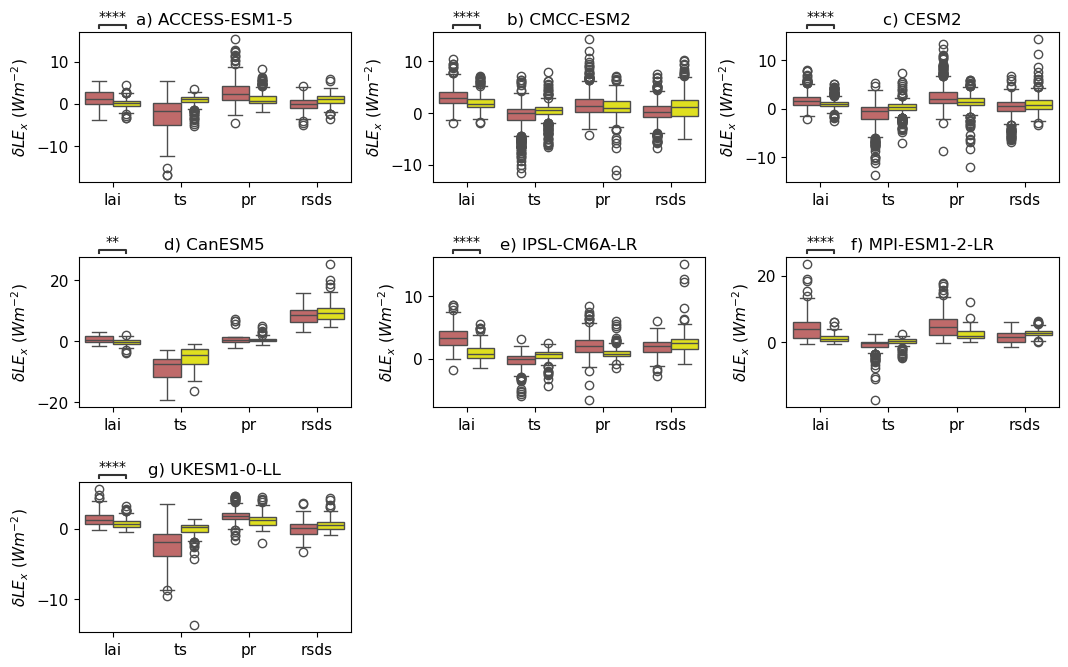

In [33]:
from statannotations.Annotator import Annotator
import seaborn.categorical


width_inch = 14
height_inch = 8

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(3, 3)
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for m, mm in enumerate(models):
    df = coef_pos_LE[m]
    
    if m < 3:
        axs = fig.add_subplot(gs[0, m])
    elif m > 2 and m < 6:
        axs = fig.add_subplot(gs[1, m-3])
    else:
        axs = fig.add_subplot(gs[2, m-6])

    axs = sns.boxplot(data=df, x='variable', y='value', hue='regime', palette=['indianred', 'yellow'])

    # axs.set_xticklabels(regions, rotation = 75)
    # axs.set_ylim(-1, 1)
    # axs.legend(loc='upper right', fontsize = 10)
    axs.legend_.remove()
    axs.set_xlabel("")
    axs.tick_params(labelsize=11)
    axs.set_ylabel("$\delta LE_{x}$ $(W m^{-2})$", fontsize = 11)
    axs.set_title(panels[m] + models[m]) 
    
    pairs = [(("lai", "water-lim"), ("lai", "energy-lim"))]
    annotator = Annotator(axs, pairs, data=df, x='variable', y='value', hue='regime')
    annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', comparisons_correction="bonferroni")
    annotator.apply_and_annotate()

# fig.tight_layout()
fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)
title = "Multilinear regression (dLEdX-1) lai"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

<>:22: SyntaxWarning: invalid escape sequence '\d'
<>:23: SyntaxWarning: invalid escape sequence '\d'
<>:24: SyntaxWarning: invalid escape sequence '\d'
<>:25: SyntaxWarning: invalid escape sequence '\d'
<>:22: SyntaxWarning: invalid escape sequence '\d'
<>:23: SyntaxWarning: invalid escape sequence '\d'
<>:24: SyntaxWarning: invalid escape sequence '\d'
<>:25: SyntaxWarning: invalid escape sequence '\d'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2910371092.py:22: SyntaxWarning: invalid escape sequence '\d'
  axs[0].set_ylabel("$\delta LE_{LAI}$ $(W m^{-2})$", fontsize = 12)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2910371092.py:23: SyntaxWarning: invalid escape sequence '\d'
  axs[1].set_ylabel("$\delta LE_{ts}$ $(W m^{-2})$", fontsize = 12)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2910371092.py:24: SyntaxWarning: invalid escape sequence '\d'
  axs[2].set_ylabel("$\delta LE_{pr}$ $(W m^{-2})$", fontsize = 12)
/var/f

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

CMCC-ESM2_water-lim vs. CMCC-ESM2_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:4.333e-44 U_stat=4.761e+05
ACCESS-ESM1-5_water-lim vs. ACCESS-ESM1-5_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.984e-14 U_stat=4.513e+04
CESM2_water-lim vs. CESM2_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:3.376e-34 U_stat=4.708e+05
CanESM5_water-lim vs. CanESM5_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.970e-02 U_stat=1.917e+03
IPSL-CM6A-LR_water-lim vs. IPSL-CM6A-LR_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.733e-46 U_stat=4.793e+04
MPI-ESM1-2-LR_water-lim vs. MPI-ESM1-2-LR_energy-lim: Mann-Whitney-Wilcoxon test two-s

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2910371092.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(models, rotation = 75)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2910371092.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(models, rotation = 75)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2910371092.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(models, rotation = 75)


<Figure size 1400x900 with 0 Axes>

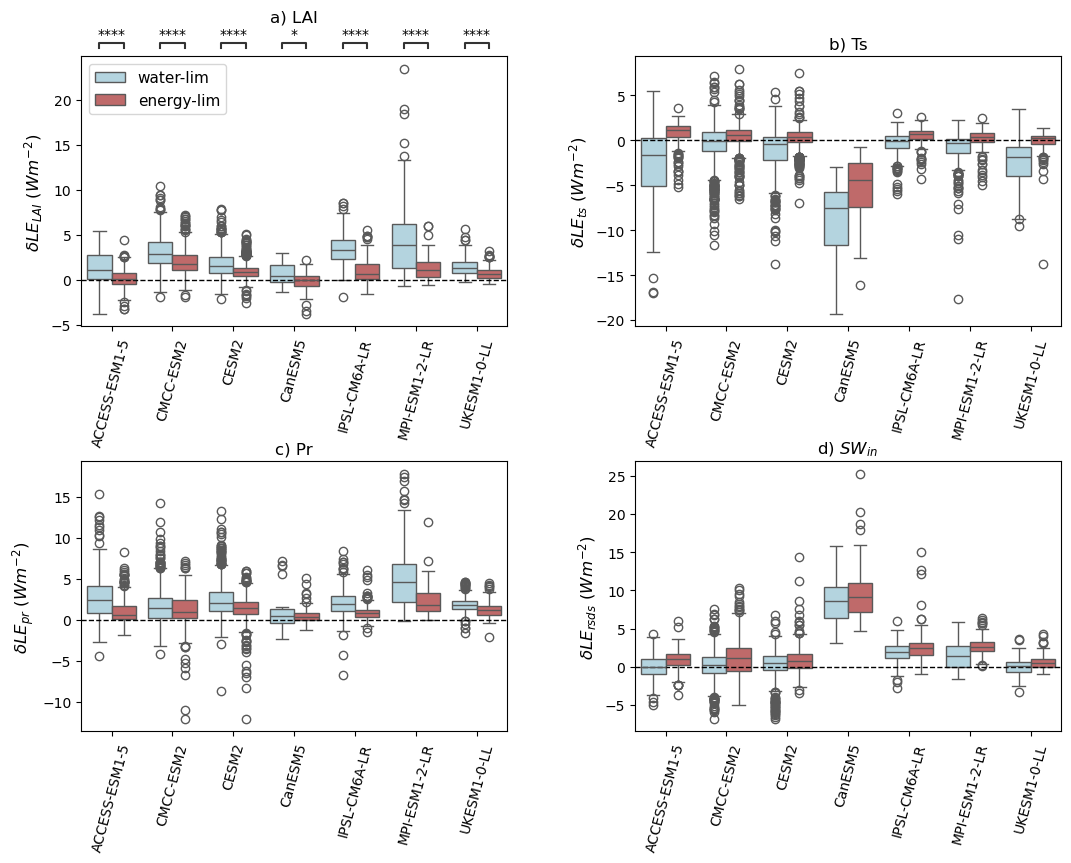

In [34]:
from statannotations.Annotator import Annotator
import seaborn.categorical


width_inch = 14
height_inch = 9

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(width_inch, height_inch))
axs = axs.flatten()
panels = ["a) LAI", "b) Ts", "c) Pr", "d) $SW_{in}$"]

for i,vv in enumerate(["lai", "ts", "pr", "rsds"]):
    df = coef_pos_LE_var[i]
    
    sns.boxplot(data=df, x='esm', y=vv, hue='regime', palette=['lightblue', 'indianred'], ax=axs[i])
    axs[i].axhline(y = 0, color = "black", linestyle="--", linewidth = 1)

    axs[i].legend_.remove()
    axs[i].set_xticklabels(models, rotation = 75)
    axs[i].set_xlabel("")
    axs[0].set_ylabel("$\delta LE_{LAI}$ $(W m^{-2})$", fontsize = 12)
    axs[1].set_ylabel("$\delta LE_{ts}$ $(W m^{-2})$", fontsize = 12)
    axs[2].set_ylabel("$\delta LE_{pr}$ $(W m^{-2})$", fontsize = 12)
    axs[3].set_ylabel("$\delta LE_{rsds}$ $(W m^{-2})$", fontsize = 12)

    if vv == "lai":
        axs[i].set_title(panels[i], y = 1.1)
        axs[i].legend(loc='upper left', bbox_to_anchor=(0, 1) ,fontsize = 11)
    
        # Generate box_pairs dynamically for the x-axis categories
        box_pairs = [
            ((esm, "water-lim"), (esm, "energy-lim"))
            for esm in df['esm'].unique()
        ]

        # Add statistical annotation
        annotator = Annotator(axs[i], box_pairs, data=df, x='esm', y=vv, hue='regime')
        annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', comparisons_correction="bonferroni",  verbose=2)
        annotator.apply_and_annotate()
    else:
        axs[i].set_title(panels[i], y = 1)

# fig.tight_layout()
fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)
title = "Multilinear regression (dLEdX-1) lai_by vars_new"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### dH/dLAI

<>:21: SyntaxWarning: invalid escape sequence '\d'
<>:22: SyntaxWarning: invalid escape sequence '\d'
<>:23: SyntaxWarning: invalid escape sequence '\d'
<>:24: SyntaxWarning: invalid escape sequence '\d'
<>:21: SyntaxWarning: invalid escape sequence '\d'
<>:22: SyntaxWarning: invalid escape sequence '\d'
<>:23: SyntaxWarning: invalid escape sequence '\d'
<>:24: SyntaxWarning: invalid escape sequence '\d'
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/3829195518.py:21: SyntaxWarning: invalid escape sequence '\d'
  axs[0].set_ylabel("$\delta H_{LAI}$ $(W m^{-2})$", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/3829195518.py:22: SyntaxWarning: invalid escape sequence '\d'
  axs[1].set_ylabel("$\delta H_{ts}$ $(W m^{-2})$", fontsize = 11)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/3829195518.py:23: SyntaxWarning: invalid escape sequence '\d'
  axs[2].set_ylabel("$\delta H_{pr}$ $(W m^{-2})$", fontsize = 11)
/var/fold

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

CMCC-ESM2_water-lim vs. CMCC-ESM2_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:3.719e-15 U_stat=2.617e+05
ACCESS-ESM1-5_water-lim vs. ACCESS-ESM1-5_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.000e+00 U_stat=2.957e+04
CESM2_water-lim vs. CESM2_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.464e-29 U_stat=2.364e+05
CanESM5_water-lim vs. CanESM5_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.000e+00 U_stat=1.224e+03
IPSL-CM6A-LR_water-lim vs. IPSL-CM6A-LR_energy-lim: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.934e-30 U_stat=1.014e+04
MPI-ESM1-2-LR_water-lim vs. MPI-ESM1-2-LR_energy-lim: Mann-Whitney-Wilcoxon test two-s

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/3829195518.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(models, rotation = 75)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/3829195518.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(models, rotation = 75)
/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/3829195518.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i].set_xticklabels(models, rotation = 75)


<Figure size 1400x900 with 0 Axes>

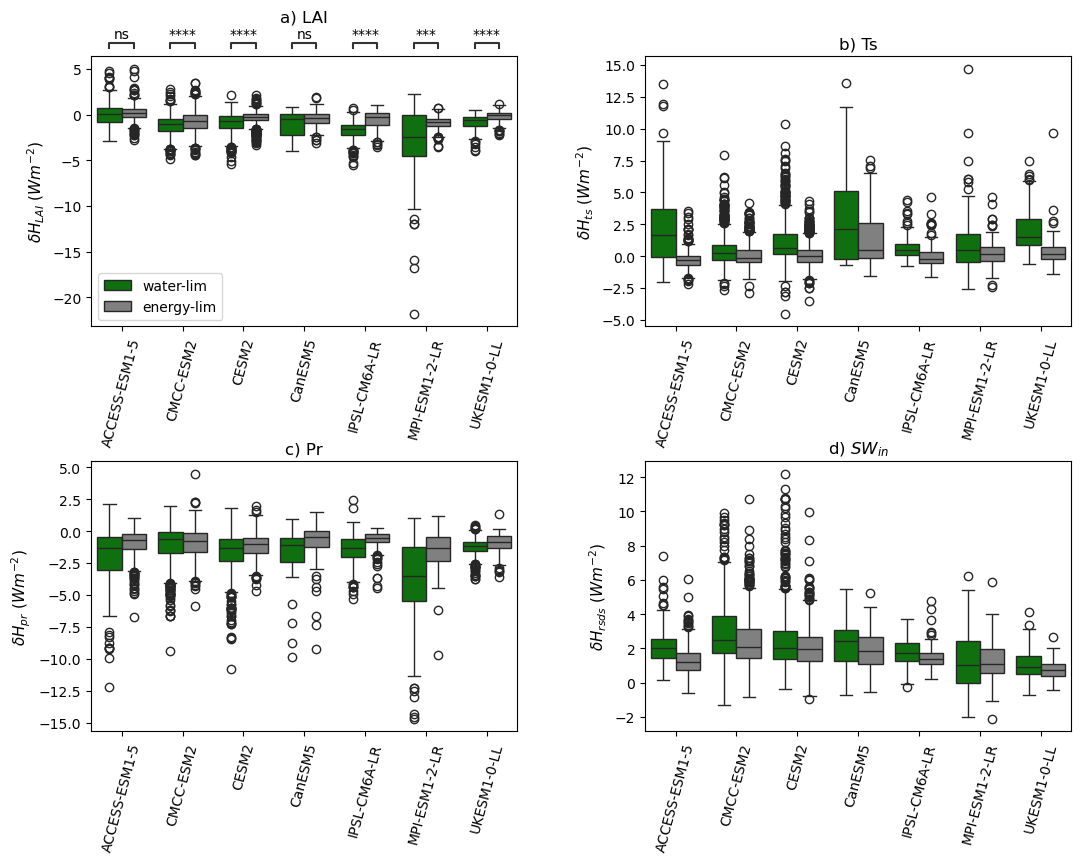

In [35]:
from statannotations.Annotator import Annotator
import seaborn.categorical


width_inch = 14
height_inch = 9

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(width_inch, height_inch))
axs = axs.flatten()
panels = ["a) LAI", "b) Ts", "c) Pr", "d) $SW_{in}$"]

for i,vv in enumerate(["lai", "ts", "pr", "rsds"]):
    df = coef_pos_H_var[i]
    
    sns.boxplot(data=df, x='esm', y=vv, hue='regime', palette=['green', 'grey'], ax=axs[i])

    axs[i].legend_.remove()
    axs[i].set_xticklabels(models, rotation = 75)
    axs[i].set_xlabel("")
    axs[0].set_ylabel("$\delta H_{LAI}$ $(W m^{-2})$", fontsize = 11)
    axs[1].set_ylabel("$\delta H_{ts}$ $(W m^{-2})$", fontsize = 11)
    axs[2].set_ylabel("$\delta H_{pr}$ $(W m^{-2})$", fontsize = 11)
    axs[3].set_ylabel("$\delta H_{rsds}$ $(W m^{-2})$", fontsize = 11)

    if vv == "lai":
        axs[i].set_title(panels[i], y = 1.1)
        axs[i].legend(loc='lower left', bbox_to_anchor=(0, 0) ,fontsize = 10)
    
        # Generate box_pairs dynamically for the x-axis categories
        box_pairs = [
            ((esm, "water-lim"), (esm, "energy-lim"))
            for esm in df['esm'].unique()
        ]

        # Add statistical annotation
        annotator = Annotator(axs[i], box_pairs, data=df, x='esm', y=vv, hue='regime')
        annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', comparisons_correction="bonferroni",  verbose=2)
        annotator.apply_and_annotate()
    else:
        axs[i].set_title(panels[i], y = 1)

# fig.tight_layout()
fig.subplots_adjust(bottom=0.2, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)
title = "Multilinear regression (dHdX-1) lai_by vars"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

## Water Availability effect of afforestation

### P-E

Understand if Net Precipitaion deficit could be the reason for the LR-induced warming experienced in Afforested regions by ACCESS, CMCC and CanESM5 

In [36]:
pr_aff_mean = []
pr_noaff_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask_aff = mask_treefrac_pos[m].notnull()
    mask_noaff = mask_treefrac_pos[m].isnull()

    data = (xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr - xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr)

    masked_aff = data.where(mask_aff)
    masked_noaff = data.where(mask_noaff)
    content_aff = masked_aff.weighted(cell_weight(masked_aff)).mean(["lat","lon"]).data
    content_noaff = masked_noaff.weighted(cell_weight(masked_noaff)).mean(["lat","lon"]).data

    pr_aff_mean.append(np.array(content_aff))
    pr_noaff_mean.append(np.array(content_noaff))

pr_noaff_mean = pd.DataFrame(pr_noaff_mean, index = models)
pr_aff_mean = pd.DataFrame(pr_aff_mean, index = models)

pr_noaff_mean = pd.melt(pr_noaff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
pr_noaff_mean["regime"] = "no A/R"

pr_aff_mean = pd.melt(pr_aff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
pr_aff_mean["regime"] = "A/R"

pr_aff_mean = pd.concat([pr_noaff_mean, pr_aff_mean], axis = 0)
pr_aff_mean = pr_aff_mean.drop(columns = "variable")

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2412434791.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(models, rotation = 75)


Text(0.5, 1.0, 'Precipitation')

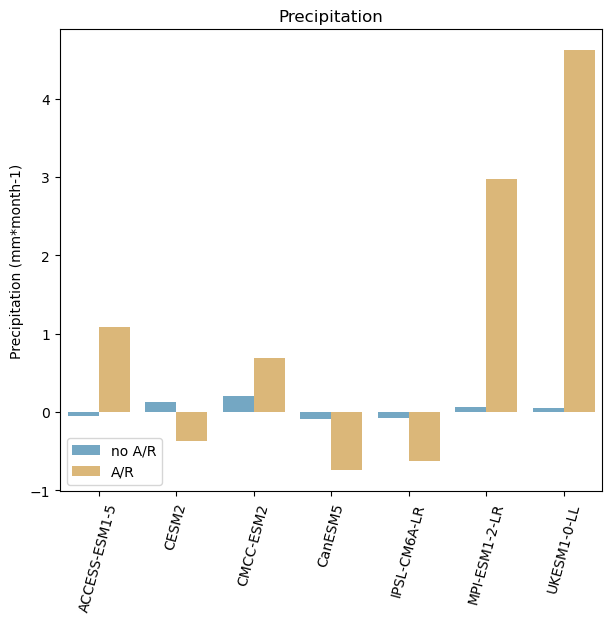

In [37]:
import seaborn as sns

models = ['ACCESS-ESM1-5',
 'CESM2',
 'CMCC-ESM2',
 'CanESM5',
 'IPSL-CM6A-LR',
 'MPI-ESM1-2-LR',
 'UKESM1-0-LL']
 
fig = plt.figure(figsize=(7, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=pr_aff_mean.sort_values("models"), hue = "regime",# errorbar=("pi", 50),
        x="models", y="value",
        palette="colorblind", alpha=.6, 
    )
ax0.set_xticklabels(models, rotation = 75)
# ax0.set_ylim(-0.35, 0.35)
ax0.legend(loc='lower left', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("Precipitation (mm*month-1)")
ax0.set_title("Precipitation")


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/751917277.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(models, rotation = 75)


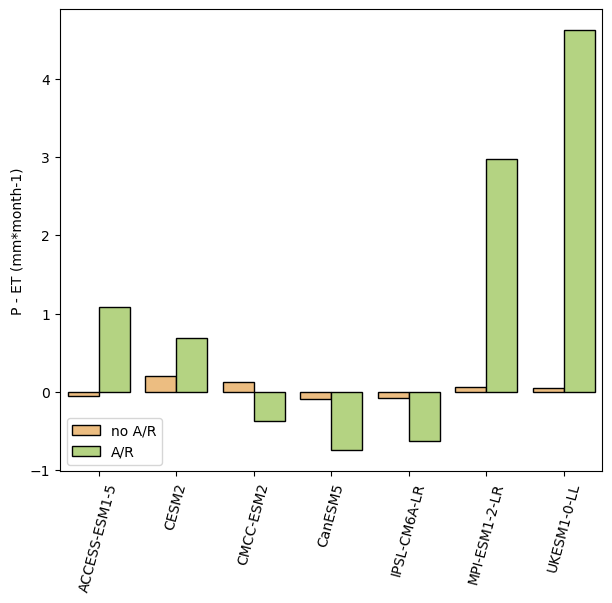

In [38]:
wa_aff_mean = []
wa_noaff_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask_aff = mask_treefrac_pos[m].notnull()
    mask_noaff = mask_treefrac_pos[m].isnull()

    data = ((xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr - xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").evspsbl) - 
            (xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr - xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").evspsbl))
    
    data = (xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr - xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr)

    masked_aff = data.where(mask_aff)
    masked_noaff = data.where(mask_noaff)
    content_aff = masked_aff.weighted(cell_weight(masked_aff)).mean(["lat","lon"]).data
    content_noaff = masked_noaff.weighted(cell_weight(masked_noaff)).mean(["lat","lon"]).data

    wa_aff_mean.append(np.array(content_aff))
    wa_noaff_mean.append(np.array(content_noaff))

wa_noaff_mean = pd.DataFrame(wa_noaff_mean, index = models)
wa_aff_mean = pd.DataFrame(wa_aff_mean, index = models)

wa_noaff_mean = pd.melt(wa_noaff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
wa_noaff_mean["regime"] = "no A/R"

wa_aff_mean = pd.melt(wa_aff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
wa_aff_mean["regime"] = "A/R"

wa_aff_mean = pd.concat([wa_noaff_mean, wa_aff_mean], axis = 0)
wa_aff_mean = wa_aff_mean.drop(columns = "variable")

import seaborn as sns

fig = plt.figure(figsize=(7, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=wa_aff_mean, hue = "regime",# errorbar=("pi", 50),
        x="models", y="value",
        palette="RdYlGn", alpha=1, edgecolor = "black"
    )
ax0.set_xticklabels(models, rotation = 75)
# ax0.set_ylim(-0.35, 0.35)
ax0.legend(loc='lower left', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("P - ET (mm*month-1)")

title = "Net precipitation, Aff"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    


/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/3686260559.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(models, rotation = 75)


Text(0.5, 1.0, 'Water availability (P-ET)')

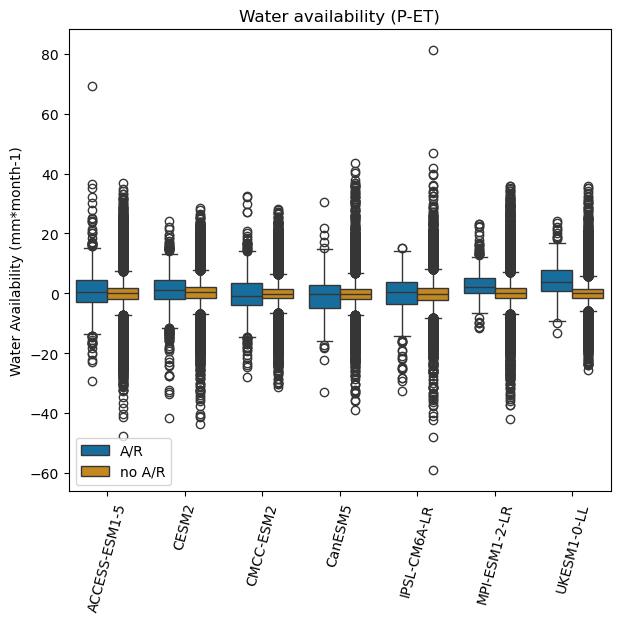

In [39]:
wa_aff_values = []
wa_noaff_values = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask_aff = mask_treefrac_pos[m].notnull()
    mask_noaff = mask_treefrac_pos[m].isnull()
    
    data = (xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim="time").pr - 
            xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim="time").pr)

    # Apply masks
    masked_aff = data.where(mask_aff)
    masked_noaff = data.where(mask_noaff)

    # Flatten and drop NaNs to get only the valid grid cell values
    # .values converted to numpy, flatten() makes it 1D, [~np.isnan(...)] removes empty cells
    vals_aff = masked_aff.values.flatten()
    vals_aff = vals_aff[~np.isnan(vals_aff)]
    
    vals_noaff = masked_noaff.values.flatten()
    vals_noaff = vals_noaff[~np.isnan(vals_noaff)]

    # Create temporary DataFrames for this specific model
    df_aff = pd.DataFrame({'models': mm, 'value': vals_aff, 'regime': 'A/R'})
    df_noaff = pd.DataFrame({'models': mm, 'value': vals_noaff, 'regime': 'no A/R'})

    wa_aff_values.append(df_aff)
    wa_noaff_values.append(df_noaff)

# Combine everything at the end
full_df = pd.concat(wa_aff_values + wa_noaff_values, axis=0)   



import seaborn as sns
fig = plt.figure(figsize=(7, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.boxplot(
        data=full_df, hue = "regime",# errorbar=("pi", 50),
        x="models", y="value",
        palette="colorblind"#, alpha=.6, 
    )
ax0.set_xticklabels(models, rotation = 75)
# ax0.set_ylim(-0.35, 0.35)
ax0.legend(loc='lower left', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("Water Availability (mm*month-1)")
ax0.set_title("Water availability (P-ET)")


In [40]:
wa_pos_water_mean = []
wa_pos_energy_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull()
    mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()

    data = ((xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr - xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").evspsbl) - 
            (xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").pr - xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = "time").evspsbl))

    masked = data.where(mask)
    masked1 = data.where(mask1)
    content = masked.weighted(cell_weight(masked)).mean(["lat","lon"]).data
    content1 = masked1.weighted(cell_weight(masked1)).mean(["lat","lon"]).data
    content = np.array(content)
    content1 = np.array(content1)
    wa_pos_water_mean.append(content); 
    wa_pos_energy_mean.append(content1);
    
wa_pos_water_mean = pd.DataFrame(wa_pos_water_mean, index = models)
wa_pos_energy_mean = pd.DataFrame(wa_pos_energy_mean, index = models)

wa_pos_water_mean = pd.melt(wa_pos_water_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
wa_pos_water_mean["regime"] = "water-lim"

wa_pos_energy_mean = pd.melt(wa_pos_energy_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
wa_pos_energy_mean["regime"] = "energy-lim"

wa_regime = pd.concat([wa_pos_water_mean, wa_pos_energy_mean], axis = 0)
wa_regime = wa_regime.drop(columns = "variable")

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/1611940605.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(models, rotation = 75)


Text(0.5, 1.0, 'Water availability (P-ET)')

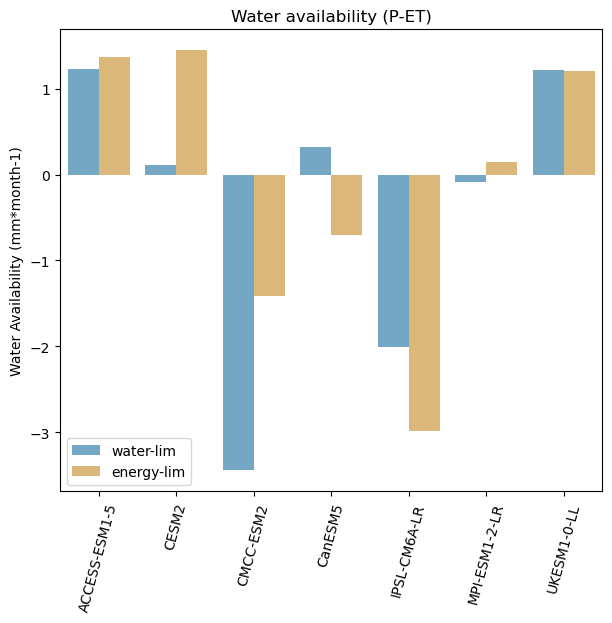

In [41]:
import seaborn as sns

fig = plt.figure(figsize=(7, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=wa_regime, hue = "regime",# errorbar=("pi", 50),
        x="models", y="value",
        palette="colorblind", alpha=.6, 
    )
ax0.set_xticklabels(models, rotation = 75)
# ax0.set_ylim(-0.35, 0.35)
ax0.legend(loc='lower left', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("Water Availability (mm*month-1)")
ax0.set_title("Water availability (P-ET)")


### Soil Water Content

In [44]:
%%capture

scenario = 'ssp370-ssp126Lu'
xr_aff_mrsol = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'mrsol_*_' + mm +'_'+ scenario + "_" + '*.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_aff_mrsol.append(content)


scenario = 'ssp370'
xr_ctl_mrsol = []
for i,mm in enumerate(models):
    filepath = glob.glob(os.path.join(data_path + 'mrsol_*_' + mm +'_'+ scenario + "_"  + '*.nc'))[0]                                       ## List of files sorted by name
    content = xr.open_dataset(filepath, drop_variables=["time_bnds","lon_bnds","lat_bnds"],engine = 'netcdf4',chunks={"time": 240})
    xr_ctl_mrsol.append(content)
    
# Rename IPSL height dimension
xr_aff_mrsol[4] = xr_aff_mrsol[4].rename({"solay": "depth"}) #.solay
xr_ctl_mrsol[4] = xr_ctl_mrsol[4].rename({"solay": "depth"}) #.solay


def xr_fix_time(xr_in, date_start, date_end):
    
    if xr_in['time'].dt.calendar == 'noleap' or xr_in['time'].dt.calendar == '360_day':
        xr_in = xr_in.convert_calendar(calendar = 'gregorian', align_on = 'date')
        
    else: None
    
    time = pd.date_range(start=date_start, end=date_end, freq='ME').to_numpy(dtype='datetime64[ns]')
    xr_out = xr_in.assign_coords(time = time)
    
    return xr_out
def xr_clean(xr_in, dims):
    data = xr_in.copy()
    for i,d in enumerate(dims):
        if d in data.coords and d in data.dims:
            data = data.drop(d)
            data = data.isel({d : 0})
        if d in data.coords:
            data = data.drop(d)
        if d in data.dims and d not in data.coords:
            data = data.isel({d : 0})
        if data.attrs == {}:
            None
        else:
            if d in data.data_vars:
                data = data.drop_vars(d)
    xr_out = data
    return xr_out
def lon180(ds):
    ds.coords['lon'] = (ds.coords['lon'] + 180) % 360 - 180
    ds = ds.sortby(ds.lon)
    return ds


for i,item in enumerate(models):
    xr_aff_mrsol[i] = xr_aff_mrsol[i].sel(lat=slice(-60,90))
    xr_ctl_mrsol[i] = xr_ctl_mrsol[i].sel(lat=slice(-60,90))
    
    xr_aff_mrsol[i] = xr_clean(xr_aff_mrsol[i], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])
    xr_ctl_mrsol[i] = xr_clean(xr_ctl_mrsol[i], ['dcpp_init_year', 'member_id', 'lon_bnds', 'lat_bnds', 'time_bnds', 'bnds'])

    xr_aff_mrsol[i] = lon180(xr_aff_mrsol[i])
    xr_ctl_mrsol[i] = lon180(xr_ctl_mrsol[i])

    xr_aff_mrsol[i] = xr_fix_time(xr_aff_mrsol[i],"2015-01","2101-01")
    xr_ctl_mrsol[i] = xr_fix_time(xr_ctl_mrsol[i],"2015-01","2101-01")



In [45]:
for i,item in enumerate(models):
    # Homogenize lat and lon
    xr_aff_mrsol[i]["lat"] = mask_treefrac_pos[i].lat; xr_aff_mrsol[i]["lon"] = mask_treefrac_pos[i].lon
    xr_ctl_mrsol[i]["lat"] = mask_treefrac_pos[i].lat; xr_ctl_mrsol[i]["lon"] = mask_treefrac_pos[i].lon

#### zonal mean values

In [46]:
mrsol_pos_water_mean = []
mrsol_pos_energy_mean = []
mrsol_noaff_mean = []
mrsol_aff_mean = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull()
    mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()
    mask2 = mask_treefrac_pos[m].isnull()
    mask3 = mask_treefrac_pos[m].notnull()

    data = ((xr_aff_mrsol[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time"]).sum(dim = ["depth"]).mrsol) - 
            (xr_ctl_mrsol[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time"]).sum(dim = ["depth"]).mrsol))

    # data = ((xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).pr - xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).evspsbl) - 
    #         (xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).pr - xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).evspsbl))

    masked = data.where(mask)
    masked1 = data.where(mask1)
    masked2 = data.where(mask2)
    masked3 = data.where(mask3)

    content = masked.weighted(cell_weight(masked)).mean(["lat","lon"]).data
    content1 = masked1.weighted(cell_weight(masked1)).mean(["lat","lon"]).data
    content2 = masked2.weighted(cell_weight(masked2)).mean(["lat","lon"]).data
    content3 = masked3.weighted(cell_weight(masked3)).mean(["lat","lon"]).data

    content = np.array(content)
    content1 = np.array(content1)
    content2 = np.array(content2)
    content3 = np.array(content3)

    mrsol_pos_water_mean.append(content); 
    mrsol_pos_energy_mean.append(content1);
    mrsol_noaff_mean.append(content2);
    mrsol_aff_mean.append(content3);

mrsol_pos_water_mean = pd.DataFrame(mrsol_pos_water_mean, index = models)
mrsol_pos_energy_mean = pd.DataFrame(mrsol_pos_energy_mean, index = models)
mrsol_noaff_mean = pd.DataFrame(mrsol_noaff_mean, index = models)
mrsol_aff_mean = pd.DataFrame(mrsol_aff_mean, index = models)


mrsol_pos_water_mean = pd.melt(mrsol_pos_water_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_pos_water_mean["regime"] = "water-lim"

mrsol_pos_energy_mean = pd.melt(mrsol_pos_energy_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_pos_energy_mean["regime"] = "energy-lim"

mrsol_noaff_mean = pd.melt(mrsol_noaff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_noaff_mean["regime"] = "no A/R"

mrsol_aff_mean = pd.melt(mrsol_aff_mean.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_aff_mean["regime"] = "A/R"

mrsol_regime = pd.concat([mrsol_pos_water_mean, mrsol_pos_energy_mean], axis = 0)
mrsol_regime = mrsol_regime.drop(columns = "variable")

mrsol_aff = pd.concat([mrsol_noaff_mean, mrsol_aff_mean], axis = 0)
mrsol_aff = mrsol_aff.drop(columns = "variable")

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/1549053154.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(models, rotation = 75)


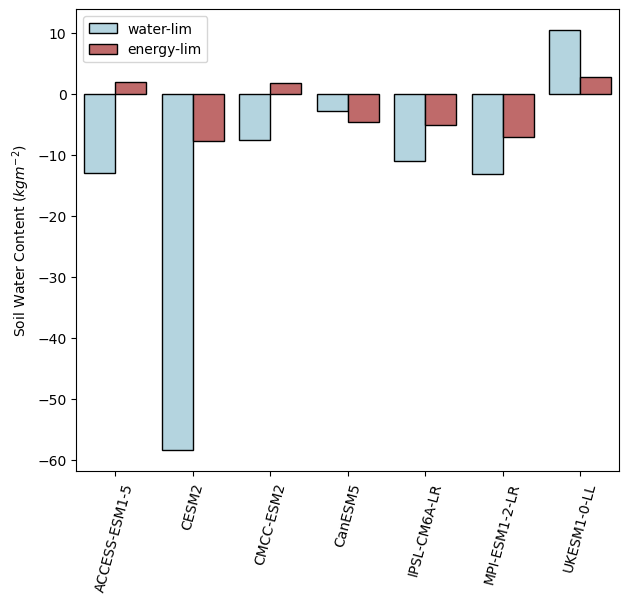

In [47]:
import seaborn as sns

fig = plt.figure(figsize=(7, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=mrsol_regime, hue = "regime",# errorbar=("pi", 50),
        x="models", y="value",
        palette=['lightblue', 'indianred'], alpha=1, edgecolor = "black"
    )
ax0.set_xticklabels(models, rotation = 75)
# ax0.set_ylim(-0.35, 0.35)
ax0.legend(loc='upper left', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("Soil Water Content ($kgm^{-2}$)")
# ax0.set_title("Water availability")

title = "Soil Water Content, water vs energy-lim"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

/var/folders/h1/tgvjn96s32q5lfh32xvkh1hh0000gp/T/ipykernel_40660/2334022282.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax0.set_xticklabels(models, rotation = 75)


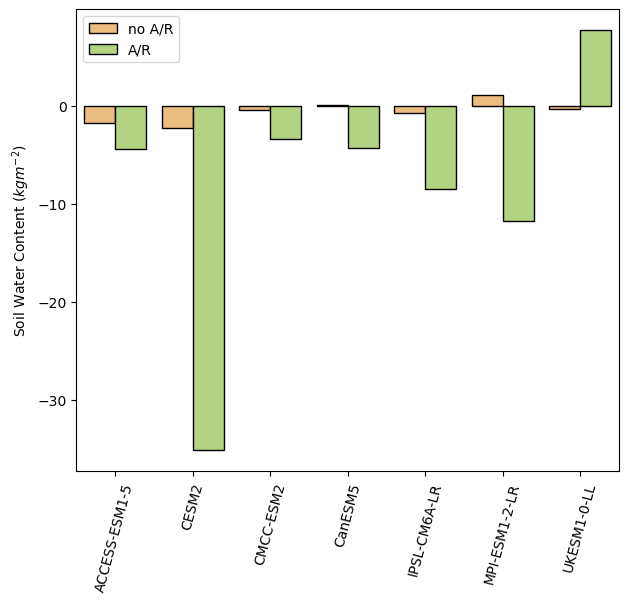

In [48]:
import seaborn as sns

fig = plt.figure(figsize=(7, 6))

ax0 = fig.add_subplot(111)
ax0 = sns.barplot(
        data=mrsol_aff, hue = "regime",# errorbar=("pi", 50),
        x="models", y="value",
        palette="RdYlGn", alpha=1, edgecolor = "black"
    )
ax0.set_xticklabels(models, rotation = 75)
# ax0.set_ylim(-0.35, 0.35)
ax0.legend(loc='upper left', fontsize = 10)
ax0.set_xlabel("")
ax0.set_ylabel("Soil Water Content ($kgm^{-2}$)")
# ax0.set_title("Water availability")

title = "Soil Water Content, aff vs no-aff"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

#### distribution of values

In [49]:
mrsol_pos_water = []
mrsol_pos_energy = []
mrsol_noaff = []
mrsol_aff = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    mask = mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull()
    mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()
    mask2 = mask_treefrac_pos[m].isnull()
    mask3 = mask_treefrac_pos[m].notnull()

    data = ((xr_aff_mrsol[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time"]).sum(dim = ["depth"]).mrsol) - 
            (xr_ctl_mrsol[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time"]).sum(dim = ["depth"]).mrsol))

    # data = ((xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).pr - xr_aff[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).evspsbl) - 
    #         (xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).pr - xr_ctl[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time", "depth"]).evspsbl))

    masked = data.where(mask)
    masked1 = data.where(mask1)
    masked2 = data.where(mask2)
    masked3 = data.where(mask3)

    masked = masked.load(); content = masked.values; content = content[~np.isnan(content)]
    masked1 = masked1.load(); content1 = masked1.values; content1 = content1[~np.isnan(content1)]
    masked2 = masked2.load(); content2 = masked2.values; content2 = content2[~np.isnan(content2)]
    masked3 = masked3.load(); content3 = masked3.values; content3 = content3[~np.isnan(content3)]

    # content = np.array(masked); content = content[~np.isnan(content)]
    # content1 = np.array(masked1); content1 = content1[~np.isnan(content1)]
    # content2 = np.array(masked2); content2 = content2[~np.isnan(content2)]
    # content3 = np.array(masked3); content3 = content3[~np.isnan(content3)]

    mrsol_pos_water.append(content); 
    mrsol_pos_energy.append(content1);
    mrsol_noaff.append(content2);
    mrsol_aff.append(content3);

mrsol_pos_water = pd.DataFrame(mrsol_pos_water, index = models)
mrsol_pos_energy = pd.DataFrame(mrsol_pos_energy, index = models)
mrsol_noaff = pd.DataFrame(mrsol_noaff, index = models)
mrsol_aff = pd.DataFrame(mrsol_aff, index = models)


mrsol_pos_water = pd.melt(mrsol_pos_water.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_pos_water["regime"] = "water-lim"

mrsol_pos_energy = pd.melt(mrsol_pos_energy.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_pos_energy["regime"] = "energy-lim"

mrsol_noaff = pd.melt(mrsol_noaff.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_noaff["regime"] = "noaff"

mrsol_aff = pd.melt(mrsol_aff.reset_index().rename(columns={'index': 'models'}), id_vars = "models")
mrsol_aff["regime"] = "aff"

mrsol_regime = pd.concat([mrsol_pos_water, mrsol_pos_energy], axis = 0)
mrsol_regime = mrsol_regime.drop(columns = "variable")

mrsol_aff = pd.concat([mrsol_noaff, mrsol_aff], axis = 0)
mrsol_aff = mrsol_aff.drop(columns = "variable")

mrsol_regime.rename(columns = {"value":"mrsol"}, inplace=True)
mrsol_aff.rename(columns = {"value":"mrsol"}, inplace=True)

In [50]:
mrsol_pos_water = []
mrsol_pos_energy = []
mrsol_noaff = []
mrsol_aff = []

for m, mm in enumerate(models):
    print("starting " + mm)
    # Define masks
    mask = mask_treefrac_pos[m].notnull() & mask_aff_water[m].notnull()
    mask1 = mask_treefrac_pos[m].notnull() & mask_aff_energy[m].notnull()
    mask2 = mask_treefrac_pos[m].isnull()
    mask3 = mask_treefrac_pos[m].notnull()

    # Get difference between AFF and CTL
    data = ((xr_aff_mrsol[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time"]).sum(dim = ["depth"]).mrsol) - 
            (xr_ctl_mrsol[m].sel(time=slice("2071-01", "2100-12")).mean(dim = ["time"]).sum(dim = ["depth"]).mrsol)).load()  # Load once

    # Apply masks (still lazy, but OK now)
    content  = data.where(mask).values.ravel()
    content1 = data.where(mask1).values.ravel()
    content2 = data.where(mask2).values.ravel()
    content3 = data.where(mask3).values.ravel()

    # Drop NaNs efficiently
    mrsol_pos_water.append(content[~np.isnan(content)])
    mrsol_pos_energy.append(content1[~np.isnan(content1)])
    mrsol_noaff.append(content2[~np.isnan(content2)])
    mrsol_aff.append(content3[~np.isnan(content3)])

    print("finished " + mm)


starting ACCESS-ESM1-5
finished ACCESS-ESM1-5
starting CESM2
finished CESM2
starting CMCC-ESM2
finished CMCC-ESM2
starting CanESM5
finished CanESM5
starting IPSL-CM6A-LR
finished IPSL-CM6A-LR
starting MPI-ESM1-2-LR
finished MPI-ESM1-2-LR
starting UKESM1-0-LL
finished UKESM1-0-LL


In [51]:
def build_long_df(data_list, models, regime_name):
    records = []
    for model, data in zip(models, data_list):
        records.extend([{"models": model, "mrsol": val, "regime": regime_name} for val in data])
    return pd.DataFrame.from_records(records)


df_water  = build_long_df(mrsol_pos_water, models, "water-lim")
df_energy = build_long_df(mrsol_pos_energy, models, "energy-lim")
df_noaff  = build_long_df(mrsol_noaff, models, "noaff")
df_aff    = build_long_df(mrsol_aff, models, "aff")

df_mrsol_regime = pd.concat([df_water, df_energy], ignore_index=True)
df_mrsol_aff    = pd.concat([df_noaff, df_aff], ignore_index=True)

df_mrsol_aff.to_csv(os.path.join(data_path, "df_mrsol_aff.csv"))
df_mrsol_regime.to_csv(os.path.join(data_path, "df_mrsol_regime.csv"))

In [52]:
df_mrsol_aff = pd.read_csv(os.path.join(data_path, "df_mrsol_aff.csv"))
df_mrsol_regime = pd.read_csv(os.path.join(data_path, "df_mrsol_regime.csv"))

ACCESS-ESM1-5
MannwhitneyuResult(statistic=np.float64(5918717.0), pvalue=np.float64(0.5559217475490728))
AFF  [-12.76, -4.97, 8.73]
NO-AFF  [0.0, -1.39, 0.0]

CESM2
MannwhitneyuResult(statistic=np.float64(25746462.5), pvalue=np.float64(9.516958256124452e-147))
AFF  [-49.13, -33.33, 5.26]
NO-AFF  [0.0, -1.27, 0.0]

CMCC-ESM2
MannwhitneyuResult(statistic=np.float64(41540368.0), pvalue=np.float64(3.63541257244678e-24))
AFF  [-6.35, -2.85, 9.71]
NO-AFF  [0.0, -0.29, 0.0]

CanESM5
MannwhitneyuResult(statistic=np.float64(394206.0), pvalue=np.float64(1.6731316245108847e-07))
AFF  [-9.56, -3.86, 2.82]
NO-AFF  [0.0, 0.11, 0.0]

IPSL-CM6A-LR
MannwhitneyuResult(statistic=np.float64(2197770.5), pvalue=np.float64(4.523466731059244e-83))
AFF  [-15.27, -8.0, -0.09]
NO-AFF  [0.0, -0.65, 0.0]

MPI-ESM1-2-LR
MannwhitneyuResult(statistic=np.float64(2271338.0), pvalue=np.float64(1.0363143835120353e-19))
AFF  [-24.5, -11.69, 4.27]
NO-AFF  [0.0, 0.84, 0.0]

UKESM1-0-LL
MannwhitneyuResult(statistic=np.float6

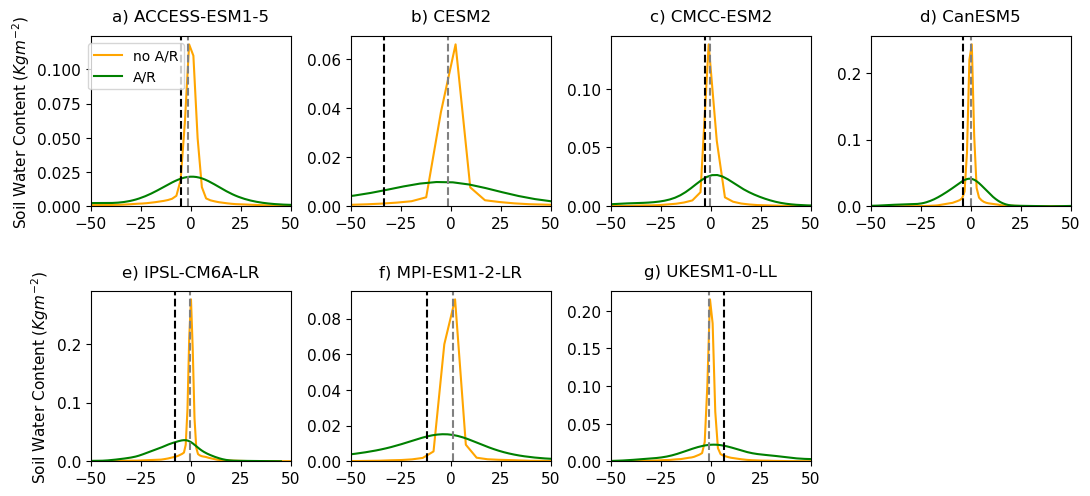

In [53]:
from statannot import add_stat_annotation
import seaborn.categorical


width_inch = 14
height_inch = 5

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(2, 4)
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for m, mm in enumerate(models):
        df = df_mrsol_aff[df_mrsol_aff["models"] == mm]
        df = df.dropna()
        if m < 4:
            axs = fig.add_subplot(gs[0, m])
        else:
            axs = fig.add_subplot(gs[1, m-4])
            
        # axs = sns.boxplot(data=df[df["regime"] == "aff"], x='models', y='mrsol', color="green")
        # axs = sns.plot(data=df[df["regime"] == "noaff"]["mrsol"].values.mean(), x='models', y='mrsol', color="orange", jitter=True, dodge=True, alpha=0.7)        # axs = sns.kdeplot(data=df[df["regime"]=="noaff"]["mrsol"], color = "orange")

        axs = sns.kdeplot(data=df[df["regime"]=="noaff"]["mrsol"], color = "orange")
        axs = sns.kdeplot(data=df[df["regime"]=="aff"]["mrsol"], color = "green")

        # axs.legend_.remove()
        axs.set_xlabel("")
        axs.tick_params(labelsize=11)
        axs.set_title(panels[m] + models[m], y = 1.04)
        # axs.label_outer()
        if m == 0:
            axs.set_ylabel("Soil Water Content ($Kgm^{-2}$)", fontsize = 11)    
            axs.legend(["no A/R", "A/R"], loc='upper right' , bbox_to_anchor=(0.5, 1), fontsize = 10)
        elif m == 4:
            axs.set_ylabel("Soil Water Content ($Kgm^{-2}$)", fontsize = 11)    
        else:
            axs.set_ylabel("")

        plt.axvline(df[df["regime"]=="noaff"]["mrsol"].mean(), color = "grey", linestyle = "--")
        plt.axvline(df[df["regime"]=="aff"]["mrsol"].mean(), color = "black", linestyle = "--")   

        axs.set_xlim(-50, 50)
   
        # add_stat_annotation(axs, data=df, x='models', y='mrsol', hue='regime',
        #                 box_pairs=[(("mrsol", "water-lim"), ("mrsol", "energy-lim"))],
        #                 test='Mann-Whitney', text_format='star', loc='outside', comparisons_correction = "bonferroni", verbose=2)
        print(mm)
        print(mannwhitneyu(df[df["regime"]=="aff"].mrsol, df[df["regime"]=="noaff"].mrsol))
        print("AFF  [" +str(np.quantile(df[df["regime"]=="aff"]["mrsol"], 0.25).round(2))+ ", " + str(df[df["regime"]=="aff"]["mrsol"].mean().round(2))+", "+
                    str(np.quantile(df[df["regime"]=="aff"]["mrsol"], 0.75).round(2)) + "]")
        print("NO-AFF  [" +str(np.quantile(df[df["regime"]=="noaff"]["mrsol"], 0.25).round(2))+ ", " + str(df[df["regime"]=="noaff"]["mrsol"].mean().round(2))+", "+
                    str(np.quantile(df[df["regime"]=="noaff"]["mrsol"], 0.75).round(2)) + "]")

        print("")
# fig.tight_layout()
fig.subplots_adjust(bottom=0.1, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)
# fig.suptitle("Linear regression (dTs/dmrsol)", y =1.2, x = 0.45)

title = "Soil Water Content, aff vs no-aff"
output_file = os.path.join(out_path, title) + "_boxplot.png"
# plt.savefig(output_file, bbox_inches='tight', dpi = 300)
    
plt.show()
plt.close()

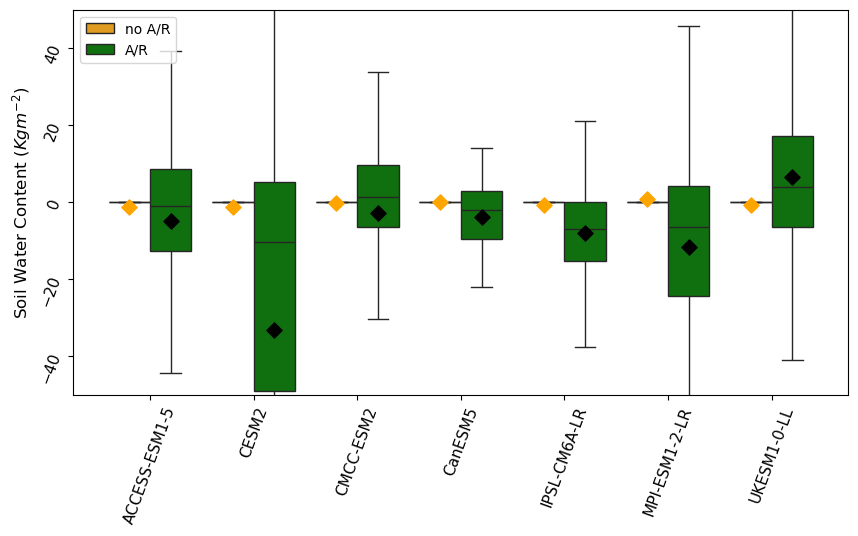

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

width_inch = 10
height_inch = 5
fig, axs = plt.subplots(figsize=(width_inch, height_inch))

# Boxplot: side-by-side by 'regime'
sns.boxplot(
    data=df_mrsol_aff,
    x='models',
    y='mrsol',
    hue='regime',
    palette={'aff': 'green', 'noaff': 'orange'},
    showfliers=False,
    ax=axs
)

# Extract the positions of each box in the plot
positions = {}
for artist in axs.patches:
    if isinstance(artist, plt.Rectangle) and artist.get_height() != 0:
        x = artist.get_x() + artist.get_width() / 2
        height = artist.get_height()
        label = artist.get_facecolor()
        positions.setdefault(round(x, 2), []).append(artist)

# compute and plot the mean
unique_models = df_mrsol_aff['models'].unique()
for i, model in enumerate(unique_models):
    for j, regime in enumerate(['aff', 'noaff']):
        subdf = df_mrsol_aff[(df_mrsol_aff['models'] == model) & (df_mrsol_aff['regime'] == regime)]
        if subdf.empty:
            continue
        mean_val = subdf['mrsol'].mean()

        # Estimate seaborn boxplot x-position: offset by hue index
        x_pos = i + (-0.2 if regime == 'noaff' else 0.2)
        axs.scatter(x_pos, mean_val,
                    color='black' if regime == 'aff' else 'orange',
                    marker='D', s=60, zorder=5)

axs.set_xlabel("", fontsize=12)
axs.set_ylabel("Soil Water Content ($Kgm^{-2}$)", fontsize=12)
axs.set_title("", fontsize=14)
axs.set_ylim(-50, 50)
axs.tick_params(labelsize=11, labelrotation = 70)

# Clean legend
handles, labels = axs.get_legend_handles_labels()
axs.legend(handles[:2], ['no A/R', 'A/R'], loc='upper left', fontsize=10)

# Save figure
output_file = os.path.join(out_path, "Soil_Water_Content_aff_vs_noaff_boxplot.png")
plt.savefig(output_file, bbox_inches='tight', dpi=500)
plt.show()
plt.close()


#### dmrsol/dLAI

In [55]:
%%capture

from sklearn import linear_model
from regressors import stats

linear = linear_model.LinearRegression()
# linear = linear_model.Ridge()

dSWT_dLAI = []
dSWT_dLAI_pval = []

for m, mm in enumerate(models):
    data = (xr_aff_mrsol[m] - xr_ctl_mrsol[m])
    lai = (xr_aff[m].lai - xr_ctl[m].lai)
    ## Preprocessing
    # Dimension time on 0th function argument to apply_ufunc with dask='parallelized' consists of multiple chunks, but is also a core dimension. 
    # To fix, either rechunk into a single dask array chunk along this dimension, i.e., ``.compute()`
    # Replace NaN and 0 with 0.01 to avoid Singular Matrix 

    # X1 = data.lai.resample(time='Y', label='left').mean().compute()

    X = data.mrsol.resample(time='Y', label='left').mean().compute()
    Y = lai.resample(time='Y', label='left').mean().compute()
    
    # 1st order detrending
    X = detrend_dim(X, "time", 1)
    Y = detrend_dim(Y, "time", 1)
    
    ## Standardization
    X = (X - X.mean(dim = ["time"]))/X.std(dim = ["time"])
    
    # Gap filling
    X = X.fillna(0.001); X = X.where(X != 0, 0.001)
    Y = Y.fillna(0.001); Y = Y.where(Y != 0, 0.001)

    coef = lag_linregress_3D(Y,X)["coef"]
    pval = lag_linregress_3D(Y,X)["pval"]

    dSWT_dLAI.append(coef)
    dSWT_dLAI_pval.append(pval)

ImportError: dlopen(/Users/matteomastropierro/miniconda/envs/geo_clim/lib/python3.13/site-packages/pyarrow/lib.cpython-313-darwin.so, 0x0002): Symbol not found: __ZN4absl12lts_2025012712log_internal10LogMessagelsIhTnNSt3__19enable_ifIXntsr4absl16HasAbslStringifyIT_EE5valueEiE4typeELi0EEERS2_RKS6_
  Referenced from: <09A493DC-7C8A-3DB5-B8FF-4F71CCCC9DB1> /Users/matteomastropierro/miniconda/envs/geo_clim/lib/libre2.11.dylib
  Expected in:     <35FB928A-2D13-39BB-82C2-48D6EB027718> /Users/matteomastropierro/miniconda/envs/geo_clim/lib/libabsl_log_internal_message.2501.0.0.dylib

In [56]:
coef_pos_noaff = []
coef_pos_aff = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    content = (dSWT_dLAI[m].where(mask_treefrac_pos[m].isnull()).stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "mrsol")
    content1 = (dSWT_dLAI[m].where(mask_treefrac_pos[m].notnull()).stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "mrsol")

    if "height" in content.columns:
        content = content.drop(columns = ["lon", "lat","height"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat","height"])
    else:
        content = content.drop(columns = ["lon", "lat"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat"])

    if hasattr(content, "type"):
        content = content.drop(columns = ["type"])
        content1 = content1.drop(columns = ["type"])
    if hasattr(content, "time"):
        content = content.drop(columns = ["time"])
        content1 = content1.drop(columns = ["time"])
    coef_pos_noaff.append(content.reset_index())
    coef_pos_aff.append(content1.reset_index())
    
    # coef_pos_noaff[m]['coef'] = coef_pos_noaff[m]['coef'].map(mapping)
    # coef_pos_aff[m]['coef'] = coef_pos_aff[m]['coef'].map(mapping)

coef_pos_SWT = []
for m,mm in enumerate(models):
    a = pd.melt(coef_pos_noaff[m].drop(columns = ["lon", "lat", "depth"])); a["regime"] = "noaff"
    b = pd.melt(coef_pos_aff[m].drop(columns = ["lon", "lat", "depth"])); b["regime"] = "aff"
    coef_pos_SWT.append(pd.concat([a,b], axis = 0))
del a, b

NameError: name 'dSWT_dLAI' is not defined

## Estimate of dTs/dLE & dTs/dLAI

In [ ]:
%%capture

from sklearn import linear_model
#from regressors import stats

linear = linear_model.LinearRegression()
# linear = linear_model.Ridge()

dTs_LE = []
dTs_LE_pval = []

for m, mm in enumerate(models):
    data = (xr_aff[m] - xr_ctl[m])
    
    ## Preprocessing
    # Dimension time on 0th function argument to apply_ufunc with dask='parallelized' consists of multiple chunks, but is also a core dimension. 
    # To fix, either rechunk into a single dask array chunk along this dimension, i.e., ``.compute()`
    # Replace NaN and 0 with 0.01 to avoid Singular Matrix 

    # X1 = data.lai.resample(time='YE', label='left').mean().compute()

    Y = data.ts.resample(time='YE', label='left').mean().compute()
    X = data.hfls.resample(time='YE', label='left').mean().compute()
    
    # 1st order detrending
    X = detrend_dim(X, "time", 1)
    Y = detrend_dim(Y, "time", 1)
    
    ## Standardization
    # X = (X - X.mean(dim = ["time"]))/X.std(dim = ["time"])
    
    # Gap filling
    X = X.fillna(0.001); X = X.where(X != 0, 0.001)
    Y = Y.fillna(0.001); Y = Y.where(Y != 0, 0.001)

    coef = lag_linregress_3D(X,Y)["coef"]
    pval = lag_linregress_3D(X,Y)["pval"]

    dTs_LE.append(coef)
    dTs_LE_pval.append(pval)

In [ ]:
dTs_LAI = []

for m, mm in enumerate(models):
    coef = coef_reg_LE[m].lai.transpose("lat","lon").data * dTs_LE[m]

    dTs_LAI.append(coef)

In [ ]:
# luc_rate = luc_rate.sel(lat = slice(-60,90))
# luc_rate = luc_rate - luc_rate.isel(time = 0)

cmap = "RdBu_r"
clevs=np.arange(-0.4,0.5,0.05)

width_inch = 14
height_inch = 8

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for i in np.arange(len(models)):
    
    data = dTs_LE[i]
    lats = data.lat
    hatch = dTs_LE_pval[i]
    
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])

    map = axs[i].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
    axs[i].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
    axs[i].coastlines()
    
    sign = np.ma.masked_greater(hatch, 0.1)
    map1 = axs[i].pcolor(lons, lats, sign, hatch = '///', transform = ccrs.PlateCarree(), alpha=0)
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)
    
    # Set subplot title
    axs[i].set_title(panels[i] + models[i])
    
    # axs[i].label_outer()
    
for i in [7,8]:
    fig.delaxes(axs[i])
        

fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("$\delta Ts_{LE}$ (K $(W m^{-2})^{-1}$)", fontsize=12)

fig.tight_layout()

title = "dTsdLE-1 map"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()

In [ ]:
# luc_rate = luc_rate.sel(lat = slice(-60,90))
# luc_rate = luc_rate - luc_rate.isel(time = 0)

cmap = "RdBu_r"
clevs=np.arange(-0.4,0.5,0.05)

width_inch = 14
height_inch = 8

fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(width_inch, height_inch), subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.flatten()
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for i in np.arange(len(models)):
    
    data = dTs_LAI[i]
    lats = data.lat
    # hatch = xr_mw_ts[i]
    
    # Add the cyclic point
    data,lons=add_cyclic_point(data,coord=data['lon'])

    map = axs[i].contourf(lons, lats, data, clevs, transform = ccrs.PlateCarree(), cmap=cmap,extend='both')
    axs[i].add_feature(cfeature.NaturalEarthFeature('physical', 'ocean', '50m', edgecolor='face', facecolor="white"))
    axs[i].coastlines()

    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,90), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()
    axs[i].xaxis.set_major_formatter(lon_formatter)

    # Latitude labels
    axs[i].set_yticks(np.arange(-60,91,45), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)
    
    # Set subplot title
    axs[i].set_title(panels[i] + models[i])
    
    # axs[i].label_outer()
    
for i in [7,8]:
    fig.delaxes(axs[i])
        

fig.subplots_adjust(bottom=0.2, top=2, left=0.1, right=0.8, wspace=0.0, hspace=0.2)

cb_ax = fig.add_axes([0.35, 0.1, 0.4, 0.02])
cbar = plt.colorbar(map, cax=cb_ax, extend='both', orientation='horizontal', fraction=0.046, pad=0.04)  
cbar.ax.set_xlabel("$\delta Ts_{LAI}$ ($K std^{-1}$)", fontsize=12)

fig.tight_layout()

title = "dTsdLAI-1 map"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)

plt.show()
plt.close()

### water & energy limited regions

In [ ]:
dTs_LAI_pos_water = []
dTs_LAI_pos_energy = []

# mapping = {0: 'lai', 1: 'ts', 2: 'pr', 3: 'rsds'}
for m,mm in enumerate(models):
    content = (dTs_LAI[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_water[m].notnull()).stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "lai")
    content1 = (dTs_LAI[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_energy[m].notnull()).stack(cell=["lon", "lat"])).dropna(dim='cell').to_dataframe(name = "lai")    
    if "height" in content.columns:
        content = content.drop(columns = ["lon", "lat","height"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat","height"]) #.dropna()
    else:
        content = content.drop(columns = ["lon", "lat"]) #.dropna()
        content1 = content1.drop(columns = ["lon", "lat"]) #.dropna()

    if hasattr(content, "type"):
        content = content.drop(columns = ["type"])
        content1 = content1.drop(columns = ["type"])
    if hasattr(content, "time"):
        content = content.drop(columns = ["time"])
        content1 = content1.drop(columns = ["time"])
    dTs_LAI_pos_water.append(content.reset_index())
    dTs_LAI_pos_energy.append(content1.reset_index())
    
    # dTs_LAI_pos_water[m]['coef'] = dTs_LAI_pos_water[m]['coef'].map(mapping)
    # dTs_LAI_pos_energy[m]['coef'] = dTs_LAI_pos_energy[m]['coef'].map(mapping)

# Remove "plev" variable from CanESM5
dTs_LAI_pos_water[3].drop(columns = "plev", inplace = True)
dTs_LAI_pos_energy[3].drop(columns = "plev", inplace = True)

In [ ]:
for m, mm in enumerate(models):
    # Process Water-limited
    ds_water = dTs_LAI[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_water[m].notnull())
    content = ds_water.stack(cell=["lon", "lat"]).dropna(dim='cell').to_dataframe(name="lai")
    
    # Process Energy-limited
    ds_energy = dTs_LAI[m].where(mask_treefrac_pos[m].notnull()).where(mask_aff_energy[m].notnull())
    content1 = ds_energy.stack(cell=["lon", "lat"]).dropna(dim='cell').to_dataframe(name="lai")    

    # CLEAN DROPS: Reset index to remove lon/lat, then drop only existing extra columns
    cols_to_drop = ["height", "type", "time", "plev"]
    
    # reset_index(drop=True) effectively deletes the 'lon' and 'lat' that were in the index
    content = content.reset_index(drop=True)
    content1 = content1.reset_index(drop=True)
    
    # Drop other metadata columns only if they exist in the dataframe
    content = content.drop(columns=[c for c in cols_to_drop if c in content.columns])
    content1 = content1.drop(columns=[c for c in cols_to_drop if c in content1.columns])

    dTs_LAI_pos_water.append(content)
    dTs_LAI_pos_energy.append(content1)

In [ ]:
dTs_LAI_pos = []
for m,mm in enumerate(models):
    a = pd.melt(dTs_LAI_pos_water[m]); a["regime"] = "water-lim"
    b = pd.melt(dTs_LAI_pos_energy[m]); b["regime"] = "energy-lim"
    dTs_LAI_pos.append(pd.concat([a,b], axis = 0))
del a, b

In [ ]:
value = 0
for m, mm in enumerate(models):
    value = np.append(value, np.mean(dTs_LAI_pos[m].value).round(3))
    print("Median dTS_dLAI for "+mm +": "+ str(np.median(dTs_LAI_pos[m].value).round(3)))

    print("Median dTS_dLAI for "+mm +" in water-lim regions: "+ str(np.mean(dTs_LAI_pos[m][dTs_LAI_pos[m]["regime"] == "water-lim"].value).round(3))
            + " +- "+ str(np.array(np.std(dTs_LAI_pos[m][dTs_LAI_pos[m]["regime"] == "water-lim"].value)).round(3)))

value = np.delete(value, 0)
print("MM Mean dTS_dLAI: " + str(np.mean(value).round(3)) + " + - "+ str(np.std(value).round(3)))

In [ ]:
from statannotations.Annotator import Annotator
import seaborn.categorical


width_inch = 13
height_inch = 6

fig = plt.figure(figsize=(width_inch, height_inch)) #, constrained_layout=True)
gs = gridspec.GridSpec(2, 4)
panels = ["a) ", "b) ", "c) ", "d) ", "e) ", "f) ", "g) "]

for m, mm in enumerate(models):
        df = dTs_LAI_pos[m]

        if m < 4:
            axs = fig.add_subplot(gs[0, m])
        else:
            axs = fig.add_subplot(gs[1, m-4])
        axs = sns.boxplot(data=df, x='variable', y='value', hue='regime', palette=['lightblue', 'indianred'])
        axs.axhline(y = 0, color = "black", linestyle="--", linewidth = 1)

        axs.legend_.remove()
        axs.set_xlabel("")
        axs.tick_params(labelsize=11)
        axs.set_title(panels[m] + models[m], y = 1.1)
        # axs.label_outer()
        if m in [0, 4]:
            axs.set_ylabel("$\delta Ts_{LAI}$ (K $std^{-1}$)", fontsize=11)     
        else:
            axs.set_ylabel("")  # Optional: Keep only if you want others without y-label
        if m == 3:   
            axs.legend(loc='upper right', bbox_to_anchor=(0.5, -0.5) ,fontsize = 10)        
        
        box_pairs=[(("lai", "water-lim"), ("lai", "energy-lim"))]
        annotator = Annotator(axs, box_pairs, data=df, x='variable', y='value', hue='regime')
        annotator.configure(test='Mann-Whitney', text_format='star', loc='outside', comparisons_correction="bonferroni",  verbose=2)
        annotator.apply_and_annotate()

fig.tight_layout()
fig.subplots_adjust(bottom=0.1, top=0.95, left=0.1, right=0.8, wspace=0.3, hspace=0.5)
# fig.suptitle("Linear regression (dTs/dLAI)", y =1.2, x = 0.45)

title = "dTsdLAI-1 boxplot"
output_file = os.path.join(out_path, title) + ".png"
plt.savefig(output_file, bbox_inches='tight', dpi = 500)
    
plt.show()
plt.close()